![Banner](../../../../Images/Banner/07_remote_sensing/09_10_banner_rs_object_detection.png)


# Field Boundary Detection in Google Satellite Screenshots (Bangladesh)

In this notebook you will recover smallholder field parcels from Google satellite screenshots of south-west Bangladesh. You will compare a classical edge detector, FC-DenseNet boundary networks trained here, and two pretrained instance models (Delineate Anything V2 and SAM 2.1), score them all on held-out test sites, and export the best result as georeferenced field polygons with `geolattice.rsense.edge_detectors`.


## Overview

Agricultural statistics, insurance, subsidies and yield models all need **field parcels**, the individual, contiguous areas that a farmer manages as one unit. Parcels are rarely available as vectors in smallholder landscapes such as the rice and vegetable lands of south-west Bangladesh, where a field can be a few hundred square metres. *Field boundary detection* (also called field delineation) is the task of recovering these parcels from imagery. It sits between two tasks that this series has already covered:

* **Semantic segmentation** (`07_08_10`) labels every pixel with a class, but touching fields of the same crop share a label and cannot be separated.
* **Object / instance detection** (`09_10_01`, `07_08_11`) returns one object per field, with a score and a shape, but every field has to be found as an object.

Field delineation can be solved in two ways, and this notebook compares both on the same data:

1. **Boundary-first (semantic edge) approach.** Predict, for every pixel, the probability $p(\text{boundary})$ that it lies on a field edge. Thresholding gives a barrier, and *connected components of the non-boundary pixels are the field instances*. This is how a classical edge detector and a fully convolutional network (**FC-DenseNet**) are used here.
2. **Instance-first approach.** Predict a set of field masks directly, with a confidence score each: **Delineate Anything V2** (a YOLO11 instance-segmentation network trained on 22.9 million field instances) and **SAM 2.1** (a promptable segmentation foundation model used in its automatic mask-generation mode).

All models are called through `geolattice.rsense.edge_detectors`, the GeoLattice module for field-boundary and field-instance detection (`build_edge_model`, `load_edge_model`, `predict_boundary_probability`, `boundary_to_instances`, `detect_field_edges`, `detect_field_edges_from_raster`, `load_delineate_anything`, `detect_delineate_anything`, `load_sam2`, `detect_sam2`). The notebook follows the protocol of `field_boundary_training.ipynb`: georeferenced screenshots with hand-digitised boundaries are split into **Train / Valid / Test sites**, settings are chosen only on the Train and Valid sites, and every model is scored once on the held-out Test sites.

> **Data caveat.** The images are screenshots of Google satellite basemaps, not a calibrated sensor product. Acquisition dates, sensors and the amount of image sharpening applied by the provider are unknown, and each tile was stored at about 1.9 cm per pixel although the real detail is much coarser (checked in *Environment and Dataset*). The ground truth is hand-digitised polylines and may miss faint boundaries. Scores therefore measure agreement with *this* digitisation at *these* ten sites.


## Core concepts

### Learning objectives

1. Frame field delineation as edge detection followed by connected-component instance extraction, and contrast it with direct instance segmentation.
2. Prepare georeferenced screenshots and polyline labels: resample to a working resolution, rasterise boundaries, and derive reference field instances.
3. Score delineations with instance-level precision/recall/F1 (IoU $> 0.5$) and with boundary F1 at metric tolerances.
4. Explain the mathematics of Sobel/Sato ridge edge detection, FC-DenseNet (dense blocks, transition layers), YOLO-style mask prototypes, and SAM 2's promptable decoder with its quality filters.
5. Train FC-DenseNet56/67/103 boundary models with GeoLattice, select the decision threshold on validation sites, and compare them with released checkpoints.
6. Use Delineate Anything V2 and SAM 2.1 through GeoLattice and tune only their inference settings.
7. Evaluate all models on held-out sites, interpret the failure modes, and export georeferenced field polygons.

### Contents

1. Environment and Dataset
2. Preparing tiles at 0.25 m and building the reference
3. Evaluation protocol: instance and boundary scores
4. Classical Edge Detection: Gradients, Ridges and `boundary_to_instances`
5. FC-DenseNet Boundary Segmentation: Architecture Mathematics, Training and Thresholds
6. Delineate Anything V2: Instance Segmentation of Fields
7. SAM 2.1 Automatic Mask Generation
8. Held-Out Test Evaluation
9. Georeferenced Field Polygons with `detect_field_edges_from_raster`
10. Limitations and a Practical Workflow
11. Summary


## Environment and Dataset

The data folder contains ten sites (`sw_01` to `sw_10`) in three splits. Each site has several `Tiles/*.TIF` screenshots (RGB, WGS 84 longitude/latitude) and a matching `Polyline/*.shp` with the digitised field boundaries. Sites, not tiles, define the split, so that the tiles of one site never appear on both sides of a split. The notebook resolves the data and the optional released checkpoints from either the notebook folder or the repository root. Heavy intermediate results are cached in a temporary folder so that a re-run is fast.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [ ]:
# Standard library: files, maths, randomness, timing, caching and package versions.
import glob, math, os, random, sys, tempfile, time, warnings, pickle, json
from pathlib import Path
from importlib.metadata import version                     # report installed package versions

import numpy as np                                          # arrays
import pandas as pd                                         # tables
import cv2                                                  # OpenCV: resizing and bilateral filter
import matplotlib.pyplot as plt                             # figures
import torch                                                # PyTorch: networks and the GPU
import torch.nn.functional as F                             # loss and activation functions
import rasterio                                             # read GeoTIFF tiles
import geopandas as gpd                                     # read the digitised boundary lines
import shapely                                              # geometry operations
from rasterio import features                               # burn vector lines into a raster
from rasterio.enums import Resampling                       # resampling methods
from rasterio.transform import Affine                       # pixel <-> map transforms
from rasterio.vrt import WarpedVRT                          # reproject a raster on the fly while reading
from rasterio.warp import calculate_default_transform       # target grid of a reprojection
from scipy import ndimage as ndi                            # morphology, labelling and distance transforms
from shapely.geometry import box                            # rectangle polygons
from skimage.color import rgb2lab                           # RGB -> CIE L*a*b* (L = lightness)
from skimage.filters import gaussian, sato                  # smoothing and ridge (line) filter
from skimage.segmentation import find_boundaries            # outline pixels of labelled regions

from geolattice.rsense import edge_detectors as ed               # GeoLattice field-edge tools

warnings.filterwarnings("ignore")                           # hide library warnings
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})
SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)   # same random numbers on every run
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"            # use the GPU when available

# Look for the data in this folder and its parents, so the notebook runs from here or from the repo root.
here = Path.cwd().resolve()
roots = [here, *here.parents]
DATA = next((r / sub for r in roots for sub in
             ("../../../../Data/08_remote_sensing/08_10_object_detection/Edge_Detection/BD_Google_Screenshot",
              "Data/08_remote_sensing/08_09_image_classification/Edge_Detection/BD_Google_Screenshot")
             if (r / sub).is_dir()), None)
if DATA is None:
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")
# Optional folder with ready-made checkpoints (FC-DenseNet and Delineate Anything); None when absent.
CKPT_ROOT = next((r / "Fieldedge-Detectors/Labeled_Data" for r in roots if (r / "Fieldedge-Detectors/Labeled_Data").is_dir()), None)
CACHE = Path(tempfile.gettempdir()) / "geolattice_edge_bd_google"   # cache for prepared tiles and trained weights
CACHE.mkdir(exist_ok=True)

# Report the environment: Python, PyTorch, device and the optional packages.
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
for p in ("rasterio", "geopandas", "scikit-image", "ultralytics", "sam2"):
    try: print(f"  {p:<14}{version(p)}")
    except Exception: print(f"  {p:<14}not installed")
print("data      :", DATA)
print("checkpoints:", CKPT_ROOT)
print("cache     :", CACHE)

Python 3.11.16 | torch 2.14.0+cu132 | device cuda (NVIDIA RTX A5500 Laptop GPU)
  rasterio      1.4.4
  geopandas     1.1.4
  scikit-image  0.26.0
  ultralytics   8.4.174
  sam2          1.1.0
data      : /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_09_image_classification/data/Edge_Detection/BD_Google_Screenshot
checkpoints: /home/zia207/Github/GeoLattice/Fieldedge-Detectors/Labeled_Data
cache     : /tmp/geolattice_edge_bd_google


In [ ]:
GSD = 0.25                        # working resolution in metres per pixel
WORK_CRS = "EPSG:9680"            # BUTM-2010 (a metric transverse-Mercator grid for Bangladesh)
MIN_FIELD_M2 = 20                 # smallest parcel kept in reference and predictions
MIN_PX = int(MIN_FIELD_M2 / GSD ** 2)   # the same limit in pixels (20 m² / 0.0625 m² = 320 px)

def res_m(src):
    # north-south pixel size in metres (the tiles are in lon/lat degrees)
    if not src.crs.is_geographic:                 # projected CRS: the resolution is already in metres
        return src.res[0]
    lat = math.radians((src.bounds.bottom + src.bounds.top) / 2)    # latitude of the tile centre
    return src.res[1] * 111_132.92 - 559.82 * math.cos(2 * lat)    # metres per degree of latitude

# One row per tile: split, site, file paths, size, CRS and pixel size.
rows = []
for split in ("Train", "Valid", "Test"):
    for site in sorted(p.name for p in (DATA / split).iterdir() if p.is_dir()):
        for tif in sorted((DATA / split / site / "Tiles").glob("*.TIF")):
            shp = DATA / split / site / "Polyline" / f"{tif.stem}.shp"     # boundary lines of the same tile
            with rasterio.open(tif) as s:
                rows.append(dict(split=split, site=site, tile=tif.stem, tif=str(tif), shp=str(shp) if shp.exists() else None,
                                 width=s.width, height=s.height, crs=s.crs.to_string(), res_cm=res_m(s) * 100,
                                 ew_m=s.width * res_m(s), ns_m=s.height * res_m(s)))
TILES = pd.DataFrame(rows)
TILES = TILES[TILES.shp.notna()].reset_index(drop=True)            # keep only tiles that have labels
SPLIT = {s: TILES[TILES.split == s].tile.tolist() for s in ("Train", "Valid", "Test")}   # tile names per split
print(f"{len(TILES)} labelled tiles:", {k: len(v) for k, v in SPLIT.items()})
# Tiles, mean pixel size (cm) and mean extent (m) per split and site.
display(TILES.groupby(["split", "site"]).agg(tiles=("tile", "size"), res_cm=("res_cm", "mean"),
                                             ew_m=("ew_m", "mean"), ns_m=("ns_m", "mean")).round(2))

60 labelled tiles: {'Train': 36, 'Valid': 12, 'Test': 12}


tiles    res_cm        ew_m        ns_m
split site                                          
Test  sw_09      6 -38078.37 -6253419.89 -4186081.88
      sw_10      6 -38022.62 -6250539.20 -4184516.56
Train sw_01      6 -37950.86 -6235832.89 -4171052.92
      sw_02      6 -37950.85 -6244496.12 -4176744.06
      sw_03      6 -38110.19 -6276557.04 -4191993.42
      sw_04      6 -38118.15 -6266814.54 -4199413.13
      sw_05      6 -38110.18 -6260550.63 -4187674.17
      sw_06      6 -38086.32 -6260820.13 -4186321.63
Valid sw_07      6 -38086.32 -6257583.12 -4184290.59
      sw_08      6 -38078.37 -6272650.11 -4186843.86

### Effective resolution of the screenshots

Each screenshot has about $16\,400 \times 11\,000$ pixels of $\approx 1.9$ cm, which would suggest centimetre-level imagery. Satellite basemaps are much coarser (typically 0.3 to 0.6 m), so most of those pixels are interpolated. A simple test removes the guesswork: reduce a crop by a factor $f$ with area averaging, enlarge it back with cubic interpolation, and measure the fraction of the variance that was lost,

$$
\text{lost}(f) = \frac{\operatorname{mean}\big[(I - \hat I_f)^2\big]}{\operatorname{Var}(I)} .
$$

If this is only a few tenths of a percent even at a pixel size of several decimetres, the screenshot contains no real detail at that scale and the tile can be processed at that coarser resolution without losing information.


In [ ]:
# How much detail do the screenshots really have? Down-sample a crop by 8 to 32 times, up-sample it
# back, and measure the share of the image variance that is lost.
res_rows = []
for t in [SPLIT[s][0] for s in ("Train", "Valid", "Test")]:          # the first tile of each split
    r = TILES.set_index("tile").loc[t]
    with rasterio.open(r.tif) as src:
        # A 4096 x 4096 px window of band 1, starting at column 4000, row 3000.
        a = src.read(1, window=rasterio.windows.Window(4000, 3000, 4096, 4096)).astype(np.float32)
    row = {"tile": t}
    for f in (8, 16, 24, 32):
        # Shrink by factor f (area average), then enlarge back to the original size (cubic).
        back = cv2.resize(cv2.resize(a, None, fx=1 / f, fy=1 / f, interpolation=cv2.INTER_AREA), a.shape[::-1], interpolation=cv2.INTER_CUBIC)
        # Lost variance in percent, labelled with the coarser pixel size in metres.
        row[f"{r.res_cm / 100 * f:.2f} m"] = np.mean((a - back) ** 2) / a.var() * 100
    res_rows.append(row)
display(pd.DataFrame(res_rows).set_index("tile").round(2).style.format("{:.2f} %")
        .set_caption("Variance lost when a 4096 x 4096 px crop is resampled to a coarser pixel size and back"))

,-3036.28 m,-6072.57 m,-9108.85 m,-12145.14 m,-3047.12 m,-6094.24 m,-9141.36 m,-12188.48 m,-3046.48 m,-6092.97 m,-9139.45 m,-12185.94 m
tile,,,,,,,,,,,,
sw_010,0.08 %,0.17 %,0.83 %,0.83 %,nan %,nan %,nan %,nan %,nan %,nan %,nan %,nan %
sw_070,nan %,nan %,nan %,nan %,0.07 %,0.17 %,0.85 %,0.73 %,nan %,nan %,nan %,nan %
sw_090,nan %,nan %,nan %,nan %,nan %,nan %,nan %,nan %,0.04 %,0.08 %,0.45 %,0.30 %


## Preparing tiles at 0.25 m and building the reference

All processing uses a **working resolution of 0.25 m** in a metric grid (BUTM-2010, EPSG:9680). A tile becomes about $1250 \times 840$ pixels, which is small enough for every model and fine enough for the narrow bunds that separate paddy plots. The warp uses area averaging; the black screenshot border is no-data and kept at 0 so that it is not blended into a dark strip that could join neighbouring fields.

**Reference boundaries.** The digitised polylines are clipped to the tile and rasterised one pixel wide (`all_touched=True`).

**Reference field instances.** Hand-drawn lines do not always meet, and many run off the tile edge, so polygonising them directly closes only some fields. Instead the boundary raster is dilated by one pixel, the image border is added to the barrier, and connected components of what remains are labelled. Components below 20 m² are dropped. This gives one integer per reference field, the same representation that the models produce.


In [ ]:
def read_tile(path):
    # Read a tile reprojected to the metric working grid (EPSG:9680, 0.25 m), RGB only.
    with rasterio.open(path) as s:
        tr, W, H = calculate_default_transform(s.crs, WORK_CRS, s.width, s.height, *s.bounds, resolution=GSD)
        # WarpedVRT reprojects while reading; "average" combines the many fine source pixels per 0.25 m pixel.
        with WarpedVRT(s, crs=WORK_CRS, transform=tr, width=W, height=H, resampling=Resampling.average,
                       src_nodata=0, nodata=0) as v:
            return v.read([1, 2, 3]).transpose(1, 2, 0), tr, v.crs, v.bounds   # (H, W, 3), transform, CRS, bounds

def prepare_tile(r):
    # Image, valid mask, boundary raster and reference field instances of one tile (cached on disk).
    cache = CACHE / f"prep_{r.tile}.pkl"
    if cache.exists():                                   # prepared before: load it
        return pickle.loads(cache.read_bytes())
    img, tr, crs, bnds = read_tile(r.tif)
    H, W = img.shape[:2]
    valid = ndi.binary_opening(img.sum(2) > 0, iterations=2)          # image pixels that are not black no-data
    lines = gpd.read_file(r.shp).to_crs(crs).geometry.clip(box(*bnds))   # boundary lines inside the tile
    lines = lines[~lines.is_empty]
    # Burn the lines into a raster: True on boundary pixels.
    bnd = features.rasterize([(l, 1) for l in lines], out_shape=(H, W), transform=tr, fill=0,
                             all_touched=True, dtype="uint8").astype(bool) & valid
    # Barrier = boundaries thickened by one pixel plus the edge of the valid area.
    barrier = ndi.binary_dilation(bnd, iterations=1) | (valid & ~ndi.binary_erosion(valid))
    inst, _ = ndi.label(valid & ~barrier)                # connected regions between barriers = reference fields
    size = np.bincount(inst.ravel()); keep = size >= MIN_PX; keep[0] = False   # drop regions below 20 m²
    inst = np.where(keep[inst], inst, 0)
    _, inst = np.unique(inst, return_inverse=True)       # renumber the fields 1, 2, 3, ...
    d = dict(img=img, valid=valid, boundary=bnd, inst=inst.reshape(H, W).astype(np.int32),
             transform=tr, crs=crs.to_string(), bounds=tuple(bnds))
    cache.write_bytes(pickle.dumps(d, protocol=4))       # save for the next run
    return d

t0 = time.time()
D = {r.tile: prepare_tile(r) for r in TILES.itertuples()}   # all tiles, keyed by tile name
print(f"prepared {len(D)} tiles in {time.time() - t0:.0f} s")
# Per tile: grid shape, number of fields, boundary pixels and median field area (m²).
summary = TILES.assign(shape=[D[t]["img"].shape[:2] for t in TILES.tile],
                       fields=[int(D[t]["inst"].max()) for t in TILES.tile],
                       boundary_px=[int(D[t]["boundary"].sum()) for t in TILES.tile],
                       median_field_m2=[float(np.median(np.bincount(D[t]["inst"].ravel())[1:])) * GSD ** 2 for t in TILES.tile])
display(summary.groupby("split").agg(tiles=("tile", "size"), fields=("fields", "sum"), mean_fields_per_tile=("fields", "mean"),
                                     median_field_m2=("median_field_m2", "median")).round(1))

prepared 60 tiles in 0 s


,tiles,fields,mean_fields_per_tile,median_field_m2
split,,,,
Test,12,891,74.2,560.9
Train,36,4169,115.8,374.3
Valid,12,1702,141.8,234.8


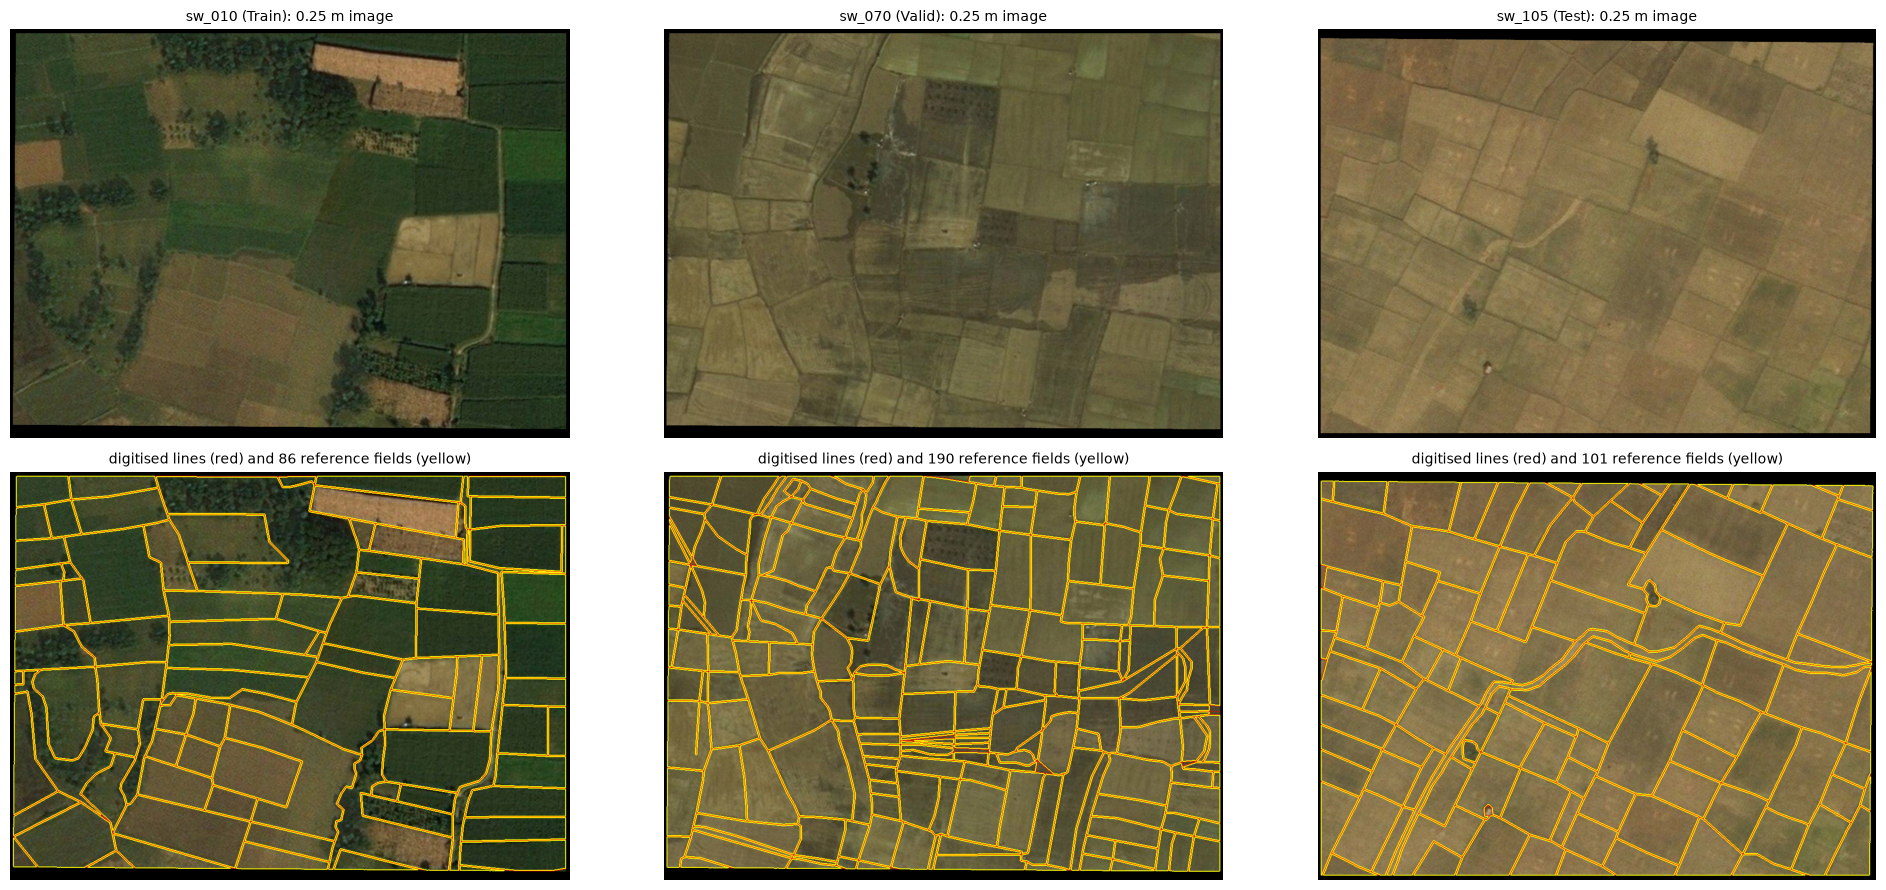

In [ ]:
# One example tile per split: the image (top) and the reference (bottom).
ex = [SPLIT["Train"][0], SPLIT["Valid"][0], SPLIT["Test"][-1]]
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for j, t in enumerate(ex):
    d = D[t]
    axes[0, j].imshow(d["img"]); axes[0, j].set_title(f"{t} ({TILES.set_index('tile').split[t]}): 0.25 m image")
    # Copy the image, paint field outlines yellow and digitised lines red.
    e = d["img"].copy(); e[find_boundaries(d["inst"])] = (255, 255, 0); e[d["boundary"]] = (255, 0, 0)
    axes[1, j].imshow(e); axes[1, j].set_title(f"digitised lines (red) and {d['inst'].max()} reference fields (yellow)")
    for a in axes[:, j]: a.axis("off")
plt.tight_layout(); plt.show()

## Evaluation protocol: instance and boundary scores

Every method in this notebook ends as an **instance-label raster** (one integer per predicted field) on the 0.25 m grid, so one protocol scores them all.

**Instance scores.** A predicted field $P$ is a true positive if it overlaps a reference field $G$ with

$$
\operatorname{IoU}(P, G) = \frac{|P \cap G|}{|P \cup G|} > 0.5 .
$$

Because IoU above 0.5 can hold for at most one pair, matching is unique. With $TP$ matches, $N_P$ predictions (of at least 20 m²) and $N_G$ reference fields,

$$
\text{precision} = \frac{TP}{N_P}, \qquad \text{recall} = \frac{TP}{N_G}, \qquad F_1 = \frac{2\,TP}{N_P + N_G} .
$$

The *mean best IoU* (for each reference field the largest IoU with any prediction) shows how well fields are matched even when they fail the 0.5 cut.

**Boundary scores.** Let $B_P$ be the predicted boundary pixels (inner edges of predicted fields) and $B_G$ the digitised boundary pixels, both restricted to the tile interior. With the Euclidean distance transform $d(\cdot, B)$ and a tolerance $\tau$ (1 m and 2 m, i.e. 4 and 8 pixels),

$$
P_\tau = \frac{|\{p \in B_P : d(p, B_G) \le \tau\}|}{|B_P|}, \qquad
R_\tau = \frac{|\{g \in B_G : d(g, B_P) \le \tau\}|}{|B_G|}, \qquad
bF_1(\tau) = \frac{2 P_\tau R_\tau}{P_\tau + R_\tau}.
$$

The tolerance accounts for the fact that a hand-drawn line and a predicted edge are never exactly on the same pixels. Instance $F_1$ is the stricter score (a single missed bund merges two fields and loses both), while boundary $F_1$ measures edge location quality.


In [ ]:
def boundary_scores(pred, d, tol_m):
    # Boundary precision, recall and F1 with a positional tolerance of tol_m metres.
    core = ndi.binary_erosion(d["valid"], iterations=4)           # ignore the outer edge of the valid area
    pb = find_boundaries(pred, mode="inner") & (pred > 0) & core  # predicted boundary pixels
    gb = d["boundary"] & core                                     # reference boundary pixels
    if pb.sum() == 0 or gb.sum() == 0:
        return 0.0, 0.0, 0.0
    tol = tol_m / GSD                                             # tolerance in pixels
    # Precision: share of predicted boundary pixels within tol of a reference boundary.
    P = float((ndi.distance_transform_edt(~gb)[pb] <= tol).mean())
    # Recall: share of reference boundary pixels within tol of a predicted boundary.
    R = float((ndi.distance_transform_edt(~pb)[gb] <= tol).mean())
    return P, R, (2 * P * R / (P + R) if P + R else 0.0)

def instance_scores(pred, d, thr=0.5):
    # Object scores: a predicted field is correct when its IoU with a reference field exceeds thr.
    gt = d["inst"]; gid = np.unique(gt[gt > 0])                   # reference field IDs
    ps = np.bincount(pred.ravel()); pid = np.where(ps >= MIN_PX)[0]; pid = pid[pid > 0]   # predicted IDs >= 20 m²
    gs = np.bincount(gt.ravel())                                  # pixels per reference field
    m = (gt > 0) & (pred > 0); K = int(pred.max()) + 1            # pixels covered by both
    if not m.any():
        return dict(precision=0.0, recall=0.0, F1=0.0, mean_best_IoU=0.0, n_pred=len(pid), n_ref=len(gid))
    # Encode each (reference, prediction) pair as one integer and count shared pixels per pair.
    pairs, cnt = np.unique(gt[m].astype(np.int64) * K + pred[m], return_counts=True)
    g_, p_ = pairs // K, pairs % K                                # decode the pair IDs
    iou = cnt / (gs[g_] + ps[p_] - cnt)                           # intersection / union per pair
    ok = (iou > thr) & np.isin(p_, pid); tp = int(ok.sum())      # IoU > 0.5 can match at most one pair per field
    best = pd.Series(iou).groupby(g_).max().reindex(gid).fillna(0)   # best IoU of each reference field
    return dict(precision=tp / max(len(pid), 1), recall=tp / max(len(gid), 1), F1=2 * tp / max(len(gid) + len(pid), 1),
                mean_best_IoU=float(best.mean()), n_pred=len(pid), n_ref=len(gid))

def evaluate(pred, d):
    # Object scores plus boundary scores at 1 m and 2 m tolerance.
    out = instance_scores(pred, d)
    for tol in (1.0, 2.0):
        P, R, Fb = boundary_scores(pred, d, tol)
        out.update({f"bP@{tol:g}m": P, f"bR@{tol:g}m": R, f"bF1@{tol:g}m": Fb})
    return out

def evaluate_set(preds, tiles):
    # One row of scores per tile.
    return pd.DataFrame([dict(tile=t, **evaluate(preds[t], D[t])) for t in tiles])

KEY = ["F1", "precision", "recall", "mean_best_IoU", "bF1@1m", "bF1@2m"]   # the scores reported below
# Sanity check 1: the reference scored against itself must be (close to) perfect.
t0_ = SPLIT["Test"][0]
chk = evaluate(D[t0_]["inst"], D[t0_])
print("sanity check, reference scored against itself:", {k: round(chk[k], 3) for k in KEY})
# Sanity check 2: a blind 100 px grid of square "fields" gives the score of guessing.
h_, w_ = D[t0_]["inst"].shape
grid_barrier = (np.arange(h_) % 100 == 0)[:, None] | (np.arange(w_) % 100 == 0)[None, :]
lab_, _ = ndi.label(~grid_barrier)
print("blind grid of 100 px cells (no image information):", {k: round(v, 3) for k, v in evaluate(lab_, D[t0_]).items() if k in KEY})

sanity check, reference scored against itself: {'F1': 1.0, 'precision': 1.0, 'recall': 1.0, 'mean_best_IoU': 1.0, 'bF1@1m': 1.0, 'bF1@2m': 1.0}
blind grid of 100 px cells (no image information): {'precision': 0.056, 'recall': 0.064, 'F1': 0.059, 'mean_best_IoU': 0.288, 'bF1@1m': 0.176, 'bF1@2m': 0.303}


## Classical Edge Detection: Gradients, Ridges and `boundary_to_instances`

Before any neural network is trained, it is worth knowing how far *unlearned* image processing gets. A field boundary is a thin line (a bund, a path, a drain, a tone change) that separates two regions of different texture. Two classical operators respond to it.

**Gradient magnitude (step edges).** For a smoothed grey image $L$ the Sobel operator estimates the partial derivatives $G_x=K_x * L$ and $G_y=K_y * L$, with $K_x=\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}$ and $K_y=K_x^{\top}$, and the edge strength is

$$|\nabla L| = \sqrt{G_x^{2}+G_y^{2}}.$$

It is large where brightness changes abruptly, such as the border between a ploughed and a green field.

**Ridge filter (line edges).** A bund is a narrow bright or dark *line*, not a step. The Hessian $H=\begin{bmatrix}L_{xx}&L_{xy}\\L_{xy}&L_{yy}\end{bmatrix}$ of the Gaussian-smoothed image has eigenvalues $\lambda_1\ge\lambda_2$. Across a bright ridge $\lambda_2\ll 0$ while $\lambda_1\approx 0$; the Sato filter responds to $\max(0,-\lambda_2)$ over several scales $\sigma$.

**Combination and normalisation.** Both maps are divided by their 99th percentile, clipped to $[0,1]$ and averaged, giving a pseudo-probability $p_{ij}$. `ed.boundary_to_instances` then applies

$$B=\{(i,j): p_{ij}\ge\tau\}\ \text{(dilated by } d \text{ px)},\qquad \text{fields}=\text{connected components of } \lnot B,$$

and drops components smaller than the minimum area. Two parameters therefore decide everything: the smoothing scale $\sigma$ and the threshold $\tau$. They are tuned on **Train** and confirmed on **Valid**; Test is not touched until the held-out test evaluation.


In [ ]:
def classical_prob(img, valid, sigma=1.5):
    # bilateral filter keeps bunds but flattens crop texture; L channel is used for the edge operators
    sm = cv2.bilateralFilter(img, 9, 25, 7)                       # edge-preserving smoothing
    L = gaussian(rgb2lab(sm)[..., 0] / 100.0, sigma)              # lightness in [0, 1], smoothed by sigma
    g = np.hypot(ndi.sobel(L, 0), ndi.sobel(L, 1))                # Sobel gradient magnitude
    # Sato ridge filter for bright and for dark thin lines (bunds can be either).
    r = sato(L, sigmas=[1, 2, 3], black_ridges=False) + sato(L, sigmas=[1, 2, 3], black_ridges=True)
    out = []
    for m in (g, r):
        s = np.percentile(m[valid], 99) if valid.any() else 1.0  # scale each map by its 99th percentile
        out.append(np.clip(m / max(s, 1e-8), 0, 1))
    p = 0.5 * (out[0] + out[1])                                   # boundary score = mean of gradient and ridge
    p[~valid] = 1.0                                               # no-data acts as a boundary
    return p.astype(np.float32)

def classical_instances(p, thr, dil=1):
    # Threshold the score and label the closed regions as fields.
    return ed.boundary_to_instances(p, threshold=thr, min_area_pixels=MIN_PX, dilate_pixels=dil)

t0 = time.time()
CP = {}
for s in (1.0, 2.0):                                              # two smoothing strengths
    CP[s] = {t: classical_prob(D[t]["img"], D[t]["valid"], s) for t in SPLIT["Train"][:12] + SPLIT["Valid"]}
print(f"classical probability maps: {time.time() - t0:.0f} s")

classical probability maps: 98 s


In [ ]:
# Grid search of the classical settings on 12 training tiles (never on the test tiles).
grid = []
sub = SPLIT["Train"][:12]
for s in CP:                                         # smoothing sigma
    for thr in (0.1, 0.15, 0.2, 0.3):                # boundary threshold
        for dil in (1, 3):                           # boundary dilation in pixels
            r = evaluate_set({t: classical_instances(CP[s][t], thr, dil) for t in sub}, sub)[KEY].mean()
            grid.append(dict(sigma=s, threshold=thr, dilate=dil, **r.round(3).to_dict()))
grid = pd.DataFrame(grid)
display(grid.sort_values("F1", ascending=False).head(6).reset_index(drop=True))   # six best settings
best_c = grid.sort_values("F1", ascending=False).iloc[0]                          # highest object F1
SIG_C, THR_C, DIL_C = float(best_c.sigma), float(best_c.threshold), int(best_c.dilate)
print(f"selected on Train subset: sigma={SIG_C}, threshold={THR_C}, dilate={DIL_C}")

,sigma,threshold,dilate,F1,precision,recall,mean_best_IoU,bF1@1m,bF1@2m
0,1.0,0.15,1,0.094,0.234,0.061,0.113,0.270,0.522
1,2.0,0.15,1,0.093,0.232,0.059,0.109,0.248,0.497
2,1.0,0.20,1,0.078,0.261,0.047,0.079,0.313,0.556
3,1.0,0.15,3,0.077,0.178,0.051,0.110,0.196,0.435
4,2.0,0.10,1,0.076,0.128,0.056,0.139,0.185,0.393
5,1.0,0.10,1,0.073,0.123,0.055,0.141,0.193,0.408


selected on Train subset: sigma=1.0, threshold=0.15, dilate=1


Valid (classical): {'F1': 0.088, 'precision': 0.285, 'recall': 0.053, 'mean_best_IoU': 0.098, 'bF1@1m': 0.331, 'bF1@2m': 0.622}


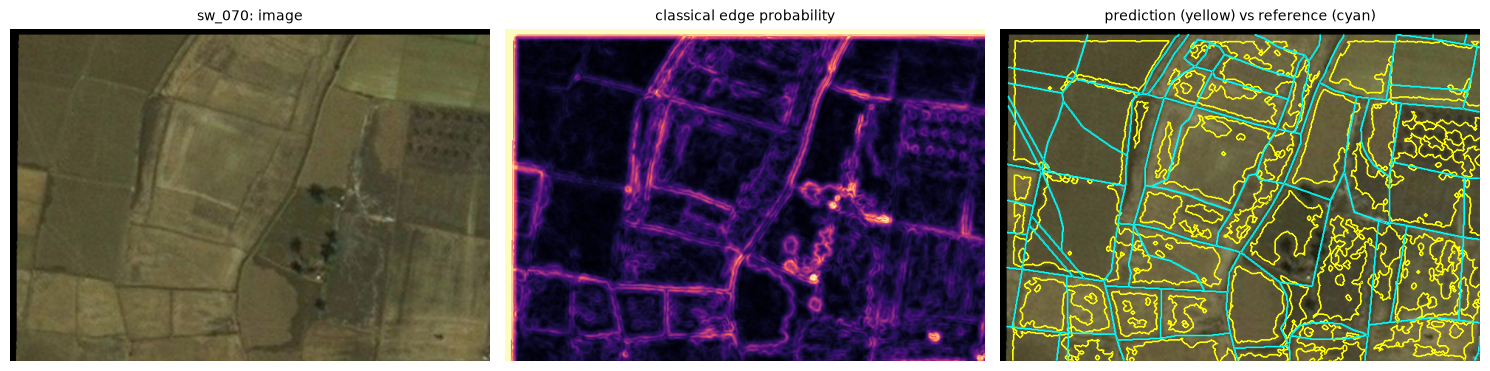

In [ ]:
# Apply the selected classical settings to the validation tiles.
vd = SPLIT["Valid"]
cv = evaluate_set({t: classical_instances(CP[SIG_C][t], THR_C, DIL_C) for t in vd}, vd)
print("Valid (classical):", cv[KEY].mean().round(3).to_dict())     # mean scores over the validation tiles

# Show one validation tile: image, edge score, and predicted vs reference boundaries.
t = vd[0]
pred = classical_instances(CP[SIG_C][t], THR_C, DIL_C)
sl = (slice(0, 450), slice(0, 650))                                 # a 450 x 650 px corner of the tile
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].imshow(D[t]["img"][sl]); ax[0].set_title(f"{t}: image")
ax[1].imshow(CP[SIG_C][t][sl], cmap="magma"); ax[1].set_title("classical edge probability")
# Outlines of the predicted fields (yellow) and the digitised lines (cyan) on the image.
ax[2].imshow(D[t]["img"][sl]); ax[2].contour(find_boundaries(pred, mode="inner")[sl], [0.5], colors="yellow", linewidths=0.6)
ax[2].contour(D[t]["boundary"][sl], [0.5], colors="cyan", linewidths=0.6); ax[2].set_title("prediction (yellow) vs reference (cyan)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## FC-DenseNet Boundary Segmentation: Architecture Mathematics, Training and Thresholds

### Why a dense network

A boundary is one or two pixels wide, so the network must keep fine spatial detail while still seeing enough context to decide that a faint line is a field edge. The FC-DenseNet (the "Tiramisu") combines a U-Net-style encoder/decoder with **dense blocks**.

**Dense block.** In a block of $L$ layers, layer $\ell$ receives the concatenation of the block input and every earlier layer output:

$$x_\ell = H_\ell\big([x_0, x_1, \dots, x_{\ell-1}]\big),$$

where $H_\ell$ is BatchNorm → ReLU → $3\times3$ convolution → dropout. With growth rate $k$, layer $\ell$ sees $c_0+(\ell-1)k$ input channels and adds $k$ new ones, so the block output has $c_0+Lk$ channels. Features are reused rather than recomputed, which keeps the parameter count small.

**Down path.** Each dense block is followed by a *transition down* (BN-ReLU-$1\times1$ conv, then $2\times2$ max-pool). Five poolings reduce a $256\times256$ crop to $8\times8$ at the bottleneck.

**Up path.** A *transition up* (stride-2 transposed convolution) restores resolution, and the result is concatenated with the **skip connection** from the matching down block before the next dense block. Skips carry the high-resolution evidence needed to place a one-pixel line.

**Output.** A $1\times1$ convolution gives logits $z_{c,ij}$ for two classes (field interior, boundary) and

$$p_{c,ij}=\frac{e^{z_{c,ij}}}{\sum_{c'}e^{z_{c',ij}}}.$$

### Loss

Boundary pixels are rare (a few percent of a tile), so plain cross-entropy would be satisfied by predicting "no boundary" everywhere. The loss used here is class-weighted cross-entropy plus a soft Dice term on the boundary class:

$$\mathcal{L}=-\frac{1}{N}\sum_{ij} w_{y_{ij}}\log p_{y_{ij},ij}\;+\;\Big(1-\frac{2\sum p_{1,ij}\,y_{ij}+\epsilon}{\sum p_{1,ij}+\sum y_{ij}+\epsilon}\Big),\qquad w_c\propto \frac{1}{\text{freq}_c^{\,1/2}}.$$

Pixels outside the image footprint are ignored.

### Presets

| preset | growth $k$ | layers per block | notes |
|---|---|---|---|
| FC-DenseNet56 | 12 | 4 in each of 11 blocks | smallest, fastest |
| FC-DenseNet67 | 16 | 5 in each of 11 blocks | middle |
| FC-DenseNet103 | 16 | 4, 5, 7, 10, 12, 15, 12, 10, 7, 5, 4 | the original Tiramisu |

All use a 48-filter first convolution, 5 pooling stages and dropout 0.2.

### Training and threshold selection

Crops of 256 px are sampled from the **Train** tiles with random 90° rotation and flips (`STEPS` Adam steps at a constant learning rate, bf16 autocast). The target is the hand-digitised line, widened by one pixel. After training, boundary probability is computed once per Valid tile with `ed.predict_boundary_probability`, and the threshold $\tau$ maximising Valid instance $F_1$ is chosen. Because the score is evaluated on the *fields* the lines enclose, the best $\tau$ is usually well below 0.5.


In [ ]:
WORK = CACHE / "fcdn"; WORK.mkdir(exist_ok=True)                   # trained weights are cached here
STEPS, BATCH, CROP, LR = 1500, 8, 256, 2e-3                          # training steps, crops per step, crop size, learning rate

TRAIN_T = SPLIT["Train"]
# Target per tile: 1 = boundary (lines thickened by one pixel), 0 = field, 255 = no-data (ignored).
target_cache = {t: np.where(D[t]["valid"], ndi.binary_dilation(D[t]["boundary"], iterations=1).astype(np.uint8), 255).astype(np.uint8) for t in TRAIN_T}
# Pixel counts of class 0 and class 1 over all training tiles.
cnt = np.bincount(np.concatenate([target_cache[t][target_cache[t] < 255].ravel() for t in TRAIN_T]), minlength=2).astype(float)
# Class weights: square root of inverse frequency, scaled to mean 1 (boundaries are rare, so they weigh more).
CLASS_W = torch.tensor((cnt.sum() / cnt) ** 0.5, dtype=torch.float32); CLASS_W = CLASS_W / CLASS_W.mean()
print("boundary share of valid pixels:", f"{cnt[1] / cnt.sum():.3%}", "| class weights:", CLASS_W.numpy().round(2))

rng = np.random.default_rng(SEED)
def sample_batch():
    # BATCH random 256 x 256 crops from random training tiles, randomly rotated and flipped.
    xs, ys = [], []
    while len(xs) < BATCH:
        t = TRAIN_T[rng.integers(len(TRAIN_T))]                      # a random tile
        H, W = D[t]["img"].shape[:2]
        r, c = rng.integers(0, H - CROP), rng.integers(0, W - CROP)  # a random top-left corner
        y = target_cache[t][r:r + CROP, c:c + CROP]
        if (y == 255).mean() > 0.3:                                  # skip crops that are mostly no-data
            continue
        x = D[t]["img"][r:r + CROP, c:c + CROP]
        k = rng.integers(4); x, y = np.rot90(x, k), np.rot90(y, k)  # rotate by 0, 90, 180 or 270 degrees
        if rng.random() < 0.5: x, y = x[:, ::-1], y[:, ::-1]        # mirror half of the crops
        xs.append(np.ascontiguousarray(x.transpose(2, 0, 1)) / 255.0); ys.append(np.ascontiguousarray(y))   # (3, H, W) in [0, 1]
    return (torch.from_numpy(np.stack(xs)).float().to(DEVICE), torch.from_numpy(np.stack(ys)).long().to(DEVICE))

def fc_loss(logits, y):
    # Weighted cross-entropy plus a soft Dice loss on the boundary class; 255 pixels are ignored.
    ce = F.cross_entropy(logits.float(), y, weight=CLASS_W.to(DEVICE), ignore_index=255)
    m = (y != 255).float(); p1 = torch.softmax(logits.float(), 1)[:, 1] * m; g = (y == 1).float()   # boundary probability and truth
    dice = 1 - (2 * (p1 * g).sum() + 1) / (p1.sum() + g.sum() + 1)
    return ce + dice

def train_fcdn(name, steps=STEPS):
    # Train one FC-DenseNet (or load its cached weights) and return (model, loss history).
    path = WORK / f"{name}.pt"
    net = ed.build_edge_model(name, num_classes=2, device=DEVICE)
    if path.exists():
        net.load_state_dict(torch.load(path, map_location=DEVICE)); return net.eval(), None
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    # One-cycle schedule: the learning rate warms up for 10 % of the steps, then decays.
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
    hist = []; net.train(); t0 = time.time()
    for it in range(steps):
        x, y = sample_batch()
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE == "cuda"):   # mixed precision on the GPU
            loss = fc_loss(net(x), y)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()   # one optimisation step
        hist.append(loss.item())
    torch.save(net.state_dict(), path)
    print(f"{name}: {steps} steps in {time.time() - t0:.0f} s, final loss {np.mean(hist[-50:]):.3f}")
    return net.eval(), hist

t0 = time.time()
FC, HIST = {}, {}
for nm in ("FC-DenseNet56", "FC-DenseNet67", "FC-DenseNet103"):
    FC[nm], HIST[nm] = train_fcdn(nm)
print(f"total {time.time() - t0:.0f} s | parameters (M):", {k: round(sum(p.numel() for p in v.parameters()) / 1e6, 2) for k, v in FC.items()})

boundary share of valid pixels: 6.812% | class weights: [0.43 1.57]


total 1 s | parameters (M): {'FC-DenseNet56': 1.38, 'FC-DenseNet67': 3.46, 'FC-DenseNet103': 9.32}


In [ ]:
# Training curves (only available when the networks were trained in this run, not loaded from the cache).
if any(h is not None for h in HIST.values()):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for k, h in HIST.items():
        if h is not None:
            ax.plot(pd.Series(h).rolling(25, min_periods=1).mean(), label=k)   # 25-step moving average of the loss
    ax.set_xlabel("step"); ax.set_ylabel("loss (CE + Dice)"); ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()
else:
    print("weights loaded from cache; training curves are only drawn on a fresh run")

weights loaded from cache; training curves are only drawn on a fresh run


[W1102 10:57:50.525011298 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 754974720 bytes (free: 173932544, total: 16760569856).


Valid inference and sweep: 96 s


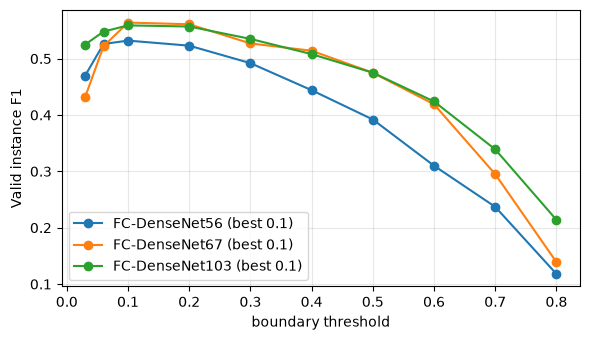

,F1,precision,recall,mean_best_IoU,bF1@1m,bF1@2m
FC-DenseNet56,0.532,0.634,0.465,0.456,0.275,0.770
FC-DenseNet67,0.564,0.634,0.514,0.476,0.248,0.736
FC-DenseNet103,0.559,0.646,0.500,0.479,0.310,0.777


In [ ]:
def prob_maps(model, tiles, bs=8, tile=512, overlap=128):
    # Boundary probability of whole tiles: overlapping 512 px windows blended with a Hann weight.
    return {t: ed.predict_boundary_probability(D[t]["img"], model, tile_size=tile, overlap=overlap, batch_size=bs,
                                               device=DEVICE, precision="bf16") for t in tiles}

THRS = np.round(np.r_[0.03, 0.06, np.arange(0.1, 0.9, 0.1)], 2)   # thresholds to try: 0.03, 0.06, 0.1, ..., 0.8
def sweep(pm, tiles):
    # Mean scores over the tiles for every threshold (no-data counts as boundary).
    rows = []
    for thr in THRS:
        r = evaluate_set({t: classical_instances(np.where(D[t]["valid"], pm[t], 1.0), thr, 1) for t in tiles}, tiles)[KEY].mean()
        rows.append(dict(threshold=thr, **r.round(3).to_dict()))
    return pd.DataFrame(rows)

t0 = time.time()
PM_V, SW, THR_FC = {}, {}, {}
for nm, net in FC.items():
    PM_V[nm] = prob_maps(net, SPLIT["Valid"])                                  # validation probabilities
    SW[nm] = sweep(PM_V[nm], SPLIT["Valid"])                                   # scores per threshold
    THR_FC[nm] = float(SW[nm].sort_values("F1", ascending=False).iloc[0].threshold)   # best validation F1
print(f"Valid inference and sweep: {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(6, 3.5))
for nm, s in SW.items():
    ax.plot(s.threshold, s.F1, "o-", label=f"{nm} (best {THR_FC[nm]:.1f})")
ax.set_xlabel("boundary threshold"); ax.set_ylabel("Valid instance F1"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
display(pd.DataFrame({nm: SW[nm].set_index("threshold").loc[THR_FC[nm]] for nm in SW}).T)   # scores at each best threshold

In [ ]:
# released checkpoints, trained on the same Train tiles in the original FieldEdge workflow
REL = {}
for nm in FC:
    p = CKPT_ROOT / "train_outputs" / "fcdn" / f"{nm}.pt"
    if p.exists():
        REL[nm] = ed.load_edge_model(p, device=DEVICE)               # the checkpoint also stores its threshold
        print(nm, "released checkpoint, stored threshold", round(float(getattr(REL[nm], "edge_threshold", np.nan)), 2))
PM_R = {nm: prob_maps(m, SPLIT["Valid"]) for nm, m in REL.items()}    # validation probabilities of the released models
# Validation scores of the released models at their stored thresholds ...
rel_rows = {nm: evaluate_set({t: classical_instances(np.where(D[t]["valid"], PM_R[nm][t], 1.0), float(REL[nm].edge_threshold), 1) for t in SPLIT["Valid"]}, SPLIT["Valid"])[KEY].mean().round(3) for nm in REL}
# ... and of the models trained here at their selected thresholds.
mine_rows = {nm: SW[nm].set_index("threshold").loc[THR_FC[nm]][KEY] for nm in FC}
display(pd.concat({"trained here": pd.DataFrame(mine_rows).T, "released": pd.DataFrame(rel_rows).T}).round(3))

FC-DenseNet56 released checkpoint, stored threshold 0.2


FC-DenseNet67 released checkpoint, stored threshold 0.3
FC-DenseNet103 released checkpoint, stored threshold 0.4


F1  precision  recall  mean_best_IoU  bF1@1m  \
trained here FC-DenseNet56   0.532      0.634   0.465          0.456   0.275   
             FC-DenseNet67   0.564      0.634   0.514          0.476   0.248   
             FC-DenseNet103  0.559      0.646   0.500          0.479   0.310   
released     FC-DenseNet56   0.241      0.346   0.186          0.260   0.145   
             FC-DenseNet67   0.308      0.450   0.238          0.293   0.178   
             FC-DenseNet103  0.341      0.504   0.262          0.308   0.202   

                             bF1@2m  
trained here FC-DenseNet56    0.770  
             FC-DenseNet67    0.736  
             FC-DenseNet103   0.777  
released     FC-DenseNet56    0.464  
             FC-DenseNet67    0.586  
             FC-DenseNet103   0.639

## Delineate Anything V2: Instance Segmentation of Fields

### From boundaries to instances

The classical and FC-DenseNet sections predicted *lines* and then recovered fields as the regions between them, so one gap in a bund merges two fields. Delineate Anything (DA) V2 predicts the **fields directly**. It is a YOLO11-seg network: a convolutional backbone and neck produce multi-scale features, and a head outputs, for each candidate $n$, a box $b_n$, a class score $s_n$ and $K$ mask coefficients $c_n\in\mathbb{R}^{K}$. A shared set of prototype masks $P\in\mathbb{R}^{K\times h\times w}$ is produced once per image, and each instance mask is a linear combination of them:

$$M_n=\sigma\Big(\sum_{k=1}^{K}c_{n,k}P_k\Big)\ \text{cropped to } b_n .$$

**Losses.** Training minimises a weighted sum of a box loss (complete IoU plus distribution focal loss), a classification loss (binary cross-entropy) and a mask loss (binary cross-entropy of $M_n$ against the reference mask):

$$\mathcal{L}=\lambda_{box}\big(1-\mathrm{CIoU}\big)+\lambda_{dfl}\mathcal{L}_{DFL}+\lambda_{cls}\mathcal{L}_{BCE}+\lambda_{seg}\mathcal{L}_{mask}.$$

**Inference.** Candidates with $s_n<\text{conf}$ are dropped, and non-maximum suppression removes overlapping masks whose IoU is above a limit. The **confidence threshold** is the one setting that matters: too high misses weak fields, too low produces duplicates and fragments. `ed.detect_delineate_anything` slides overlapping windows over the tile and merges the results.

Two checkpoints are compared: the **pre-trained** DA V2 (trained on a global multi-resolution field dataset) and a **fine-tuned** copy that was adapted to these Bangladesh screenshots by the FieldEdge workflow on the same Train tiles. Only the confidence is tuned here, on Valid.


In [ ]:
PRED = CACHE / "preds"; PRED.mkdir(exist_ok=True)                   # cached label maps of every method

def cached_pred(key, tile, fn):
    # Return a cached prediction, or compute it with fn() and cache it.
    p = PRED / f"{key}_{tile}.npy"
    if p.exists():
        return np.load(p)
    out = np.asarray(fn(), dtype=np.int32)
    np.save(p, out); return out

def clean(lab, tile):
    # remove anything outside the image footprint and relabel compactly
    lab = np.where(D[tile]["valid"], lab, 0)
    _, inv = np.unique(lab, return_inverse=True)                      # IDs 0, 1, 2, ... without gaps
    return inv.reshape(lab.shape).astype(np.int32)

# Load the Delineate Anything V2 checkpoints that exist: pretrained, and fine-tuned on the Train tiles.
DA = {}
for nm, rel in (("DA pretrained", "checkpoints/DelineateAnythingv2.pt"), ("DA fine-tuned", "train_outputs/da/runs/finetune/weights/best.pt")):
    p = CKPT_ROOT / rel
    if p.exists():
        DA[nm] = ed.load_delineate_anything(p, device=DEVICE)
print("loaded:", list(DA))

def run_da(nm, tile, conf):
    # Field instances of one tile from Delineate Anything at confidence conf (cached).
    key = f"{nm.replace(' ', '_')}_c{conf}"
    return clean(cached_pred(key, tile, lambda: ed.detect_delineate_anything(
        D[tile]["img"], DA[nm], tile_size=512, confidence=conf, min_area_pixels=MIN_PX).labels), tile)

# Choose the confidence threshold of each model on the validation tiles.
t0 = time.time()
CONFS = (0.02, 0.05, 0.15, 0.3, 0.5)
da_rows = []
for nm in DA:
    for conf in CONFS:
        r = evaluate_set({t: run_da(nm, t, conf) for t in SPLIT["Valid"]}, SPLIT["Valid"])[KEY].mean()
        da_rows.append(dict(model=nm, confidence=conf, **r.round(3).to_dict()))
da_tab = pd.DataFrame(da_rows)
display(da_tab)
CONF_DA = {nm: float(da_tab[da_tab.model == nm].sort_values("F1", ascending=False).iloc[0].confidence) for nm in DA}
print(f"{time.time() - t0:.0f} s | selected confidence on Valid:", CONF_DA)

loaded: ['DA pretrained', 'DA fine-tuned']


,model,confidence,F1,precision,recall,mean_best_IoU,bF1@1m,bF1@2m
0,DA pretrained,0.02,0.368,0.411,0.345,0.397,0.581,0.720
1,DA pretrained,0.05,0.373,0.456,0.325,0.377,0.576,0.713
2,DA pretrained,0.15,0.361,0.526,0.284,0.325,0.546,0.675
3,DA pretrained,0.30,0.298,0.565,0.210,0.237,0.479,0.594
4,DA pretrained,0.50,0.179,0.634,0.108,0.117,0.312,0.397
5,DA fine-tuned,0.02,0.491,0.466,0.530,0.531,0.644,0.787
6,DA fine-tuned,0.05,0.506,0.500,0.523,0.523,0.647,0.791
7,DA fine-tuned,0.15,0.519,0.534,0.514,0.514,0.646,0.789
8,DA fine-tuned,0.30,0.532,0.579,0.501,0.499,0.642,0.784
9,DA fine-tuned,0.50,0.527,0.640,0.457,0.451,0.624,0.764


28 s | selected confidence on Valid: {'DA pretrained': 0.05, 'DA fine-tuned': 0.3}


## SAM 2.1 Automatic Mask Generation

SAM 2.1 is a promptable, *class-agnostic* segmentation model. It was never trained to know what a "field" is; it segments whatever coherent regions it finds. Used without prompts, the **automatic mask generator** places a grid of point prompts over the tile and keeps the masks that look reliable.

**Architecture.** A Hiera hierarchical vision transformer encodes the image into features $F$. A prompt encoder maps a point $(x,y)$ to an embedding $e_p$, and a two-way transformer mask decoder lets the prompt tokens and the image features attend to each other. It outputs candidate masks $M_m$ and a predicted IoU $\hat q_m$ for each.

**Filtering.** A mask is kept only if both quality scores are high:

$$\hat q_m\ge\tau_{iou},\qquad S_m=\frac{|\{z_{ij}>\theta+\delta\}|}{|\{z_{ij}>\theta-\delta\}|}\ge\tau_{stab},$$

where $z$ are the mask logits, $\theta$ the binarisation threshold and $\delta$ an offset. The **stability score** $S_m$ is high when the mask hardly changes as the threshold moves. Duplicates are then removed by NMS. `ed.detect_sam2` runs this in overlapping windows and drops masks above `max_area_fraction` of a window (typically the background) or below the minimum field area.

The grid of point prompts and the two thresholds are the knobs. They are tuned on three **Valid** tiles only, because SAM 2 is much slower than the other models.


In [ ]:
os.environ.setdefault("HF_HUB_OFFLINE", "1")            # use the cached Hugging Face weights, no download
t0 = time.time()
SAM = ed.load_sam2(device=DEVICE)                       # SAM 2.1 (large) automatic mask generator
print(f"SAM 2.1 loaded in {time.time() - t0:.0f} s")

def run_sam(tile, pts=32, iou=0.8, stab=0.9):
    # SAM 2.1 masks of one tile, as field labels (cached). pts = prompt points per side,
    # iou = minimum predicted mask quality, stab = minimum mask stability.
    key = f"sam2_p{pts}_i{iou}_s{stab}"
    return clean(cached_pred(key, tile, lambda: ed.detect_sam2(
        D[tile]["img"], SAM, tile_size=1024, overlap=192, min_area_pixels=MIN_PX,
        generator_kwargs=dict(points_per_side=pts, pred_iou_thresh=iou, stability_score_thresh=stab)).labels), tile)

t0 = time.time(); _ = run_sam(SPLIT["Valid"][0]); print(f"one tile: {time.time() - t0:.0f} s")   # time one tile

SAM 2.1 loaded in 2 s
one tile: 0 s


In [ ]:
# SAM is slow, so three settings are compared on three validation tiles only.
t0 = time.time()
sub = SPLIT["Valid"][::4][:3]                                # every fourth validation tile, at most three
sam_rows = []
for pts, iou, stab in [(32, 0.8, 0.9), (32, 0.7, 0.85), (32, 0.88, 0.95)]:   # default, looser, stricter
    r = evaluate_set({t: run_sam(t, pts, iou, stab) for t in sub}, sub)[KEY].mean()
    sam_rows.append(dict(points_per_side=pts, pred_iou=iou, stability=stab, **r.round(3).to_dict()))
sam_tab = pd.DataFrame(sam_rows); display(sam_tab)
b = sam_tab.sort_values("F1", ascending=False).iloc[0]       # the setting with the best object F1
SAM_CFG = (int(b.points_per_side), float(b.pred_iou), float(b.stability))
print(f"{time.time() - t0:.0f} s | selected:", SAM_CFG)

,points_per_side,pred_iou,stability,F1,precision,recall,mean_best_IoU,bF1@1m,bF1@2m
0,32,0.80,0.90,0.239,0.635,0.148,0.173,0.456,0.531
1,32,0.70,0.85,0.284,0.597,0.191,0.223,0.514,0.619
2,32,0.88,0.95,0.060,0.574,0.032,0.042,0.193,0.223


2 s | selected: (32, 0.7, 0.85)


## Held-Out Test Evaluation

Every setting is now frozen: the classical $(\sigma,\tau)$, the three FC-DenseNet thresholds, the two DA confidences and the SAM 2 prompt grid. All models are scored once on the 12 **Test** tiles (sites sw_09 and sw_10, never used for training or tuning) with the same instance and boundary metrics.


In [ ]:
# Every method, with the settings chosen on Train/Valid, applied once to the held-out Test tiles.
TEST = SPLIT["Test"]
t0 = time.time()
cp_test = {t: classical_prob(D[t]["img"], D[t]["valid"], SIG_C) for t in TEST}
P = {"Classical (Sobel+Sato)": {t: classical_instances(cp_test[t], THR_C, DIL_C) for t in TEST}}
for nm, net in FC.items():                                   # FC-DenseNets trained in this notebook
    pm = prob_maps(net, TEST)
    P[f"{nm} (trained here)"] = {t: classical_instances(np.where(D[t]["valid"], pm[t], 1.0), THR_FC[nm], 1) for t in TEST}
for nm, m in REL.items():                                    # released FC-DenseNet checkpoints
    pm = prob_maps(m, TEST)
    P[f"{nm} (released)"] = {t: classical_instances(np.where(D[t]["valid"], pm[t], 1.0), float(m.edge_threshold), 1) for t in TEST}
for nm in DA:                                                # Delineate Anything models
    P[nm] = {t: run_da(nm, t, CONF_DA[nm]) for t in TEST}
P["SAM 2.1 (auto masks)"] = {t: run_sam(t, *SAM_CFG) for t in TEST}
print(f"predictions: {time.time() - t0:.0f} s")

# Scores per model and tile, then the mean per model, best first.
PER = pd.concat({k: evaluate_set(v, TEST) for k, v in P.items()}, names=["model"]).reset_index(level=0)
SUM = PER.groupby("model")[KEY].mean().sort_values("F1", ascending=False)
display(SUM.round(3))

predictions: 49 s


,F1,precision,recall,mean_best_IoU,bF1@1m,bF1@2m
model,,,,,,
FC-DenseNet103 (trained here),0.640,0.625,0.705,0.627,0.296,0.744
FC-DenseNet67 (trained here),0.621,0.575,0.720,0.620,0.226,0.683
FC-DenseNet56 (trained here),0.607,0.608,0.654,0.587,0.251,0.723
SAM 2.1 (auto masks),0.550,0.719,0.470,0.453,0.608,0.738
DA fine-tuned,0.503,0.445,0.613,0.582,0.599,0.731
DA pretrained,0.419,0.435,0.417,0.455,0.538,0.671
FC-DenseNet103 (released),0.359,0.453,0.323,0.353,0.180,0.578
FC-DenseNet67 (released),0.319,0.403,0.288,0.331,0.155,0.526
FC-DenseNet56 (released),0.230,0.270,0.220,0.299,0.109,0.386


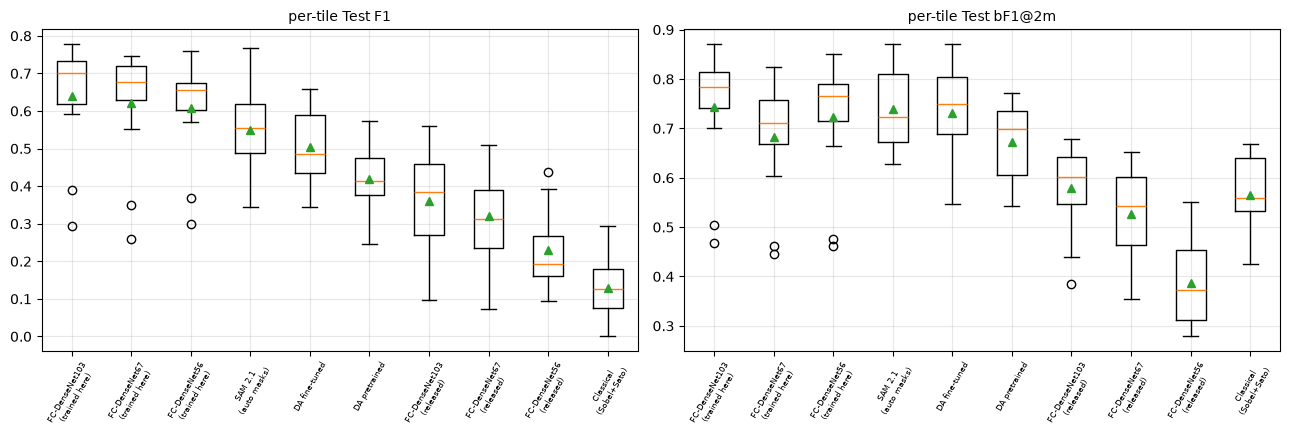

best model on Test: FC-DenseNet103 (trained here)


site,sw_09,sw_10
model,,
FC-DenseNet103 (trained here),0.608,0.673
FC-DenseNet67 (trained here),0.574,0.668
FC-DenseNet56 (trained here),0.579,0.635
SAM 2.1 (auto masks),0.605,0.495
DA fine-tuned,0.542,0.465
DA pretrained,0.464,0.373
FC-DenseNet103 (released),0.272,0.446
FC-DenseNet67 (released),0.255,0.384
FC-DenseNet56 (released),0.222,0.239


In [ ]:
# Spread of the per-tile scores: object F1 and boundary F1 at 2 m.
order = SUM.index.tolist()                                   # models from best to worst
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, k in zip(ax, ("F1", "bF1@2m")):
    a.boxplot([PER[PER.model == m][k] for m in order], tick_labels=[m.replace(" (", "\n(") for m in order], showmeans=True)
    a.set_title(f"per-tile Test {k}"); a.tick_params(axis="x", labelsize=6, rotation=60); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

best_m = SUM.index[0]
print("best model on Test:", best_m)
# Mean object F1 per site (the site code "sw_NN" is taken from the tile name) and model.
site = PER.assign(site=PER.tile.str.extract(r"(sw_\d\d)")[0]).groupby(["site", "model"])["F1"].mean().unstack().T.loc[order]
display(site.round(3))

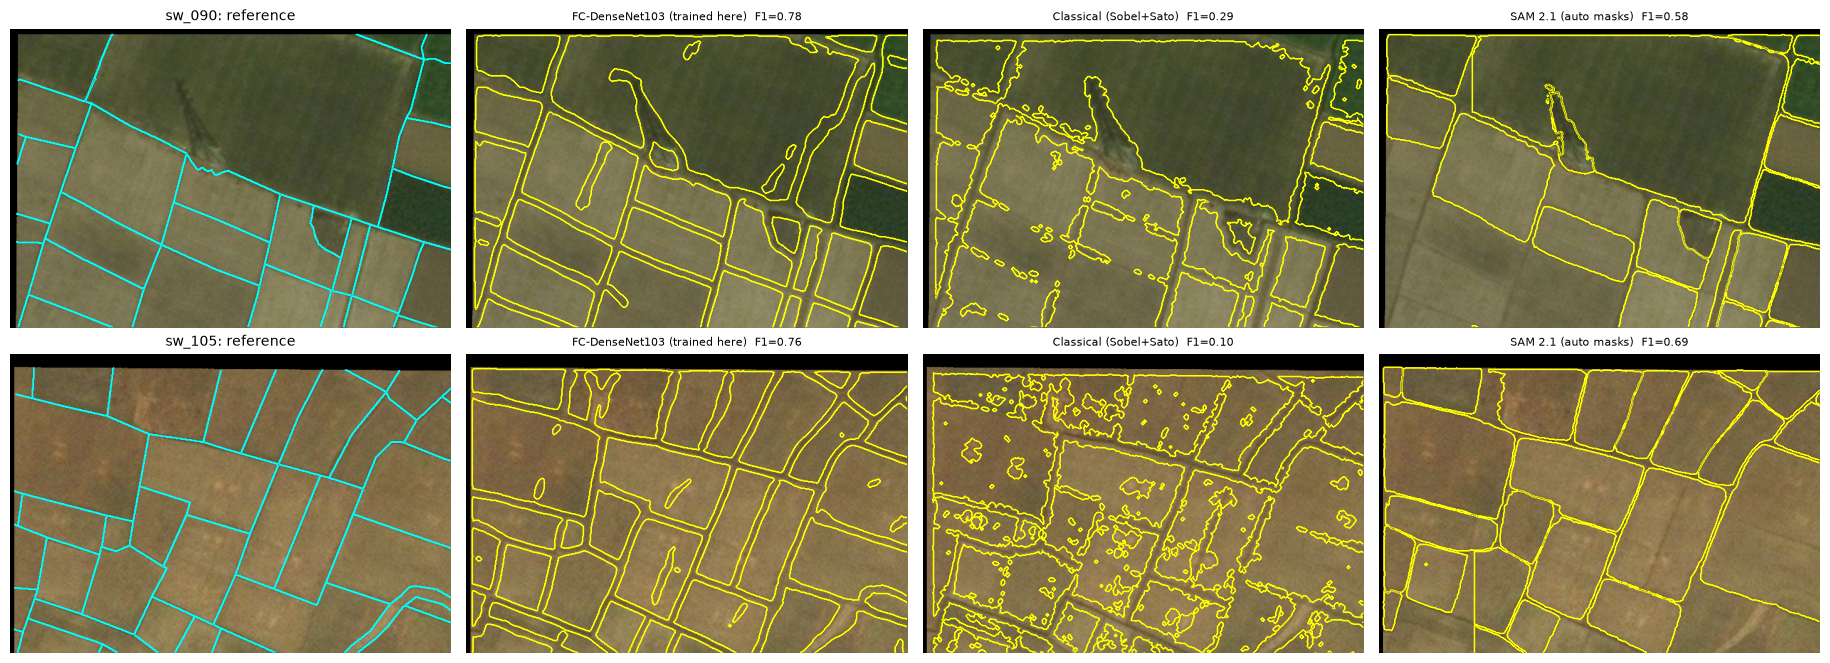

In [ ]:
# The best model, the classical baseline and SAM 2.1 on two test tiles.
show = [best_m, "Classical (Sobel+Sato)", "SAM 2.1 (auto masks)"]
show = list(dict.fromkeys(show))                             # drop a duplicate if the best model is one of the others
tiles = [TEST[0], TEST[-1]]
sl = (slice(0, 420), slice(0, 620))                          # a 420 x 620 px corner of each tile
fig, ax = plt.subplots(len(tiles), len(show) + 1, figsize=(4.6 * (len(show) + 1), 3.4 * len(tiles)))
for i, t in enumerate(tiles):
    ax[i, 0].imshow(D[t]["img"][sl]); ax[i, 0].contour(D[t]["boundary"][sl], [0.5], colors="cyan", linewidths=0.7)   # reference lines
    ax[i, 0].set_title(f"{t}: reference")
    for j, m in enumerate(show, 1):
        ax[i, j].imshow(D[t]["img"][sl]); b_ = find_boundaries(P[m][t], mode="inner")    # outlines of predicted fields
        ax[i, j].contour(b_[sl], [0.5], colors="yellow", linewidths=0.6)
        ax[i, j].set_title(f"{m}  F1={evaluate(P[m][t], D[t])['F1']:.2f}", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## Georeferenced Field Polygons with `detect_field_edges_from_raster`

Scores on label rasters are useful for comparing models, but a mapping product is a set of **georeferenced polygons**. `ed.detect_field_edges_from_raster` reads a GeoTIFF, runs the boundary model with overlap blending, converts the instance raster to polygons with the raster's own transform and CRS, and returns field area and perimeter in square metres and metres (this requires a projected CRS).

The raw screenshots are in EPSG:4326 at about 2 cm, a scale the networks never saw. The tile is therefore first written as a 0.25 m GeoTIFF in the metric working CRS, and the best FC-DenseNet model from the FC-DenseNet section (by Valid $F_1$) is applied to it.


In [ ]:
# The FC-DenseNet with the best validation F1, applied to a GeoTIFF on disk to get georeferenced polygons.
best_fc = max(THR_FC, key=lambda k: SW[k].set_index("threshold").loc[THR_FC[k], "F1"])
tile = TEST[0]; d = D[tile]
OUT = CACHE / "export"; OUT.mkdir(exist_ok=True)
tif = OUT / f"{tile}_025m.tif"
# Write the 0.25 m RGB tile as a GeoTIFF with its CRS and transform.
with rasterio.open(tif, "w", driver="GTiff", height=d["img"].shape[0], width=d["img"].shape[1], count=3, dtype="uint8",
                   crs=d["crs"], transform=d["transform"], compress="deflate") as dst:
    dst.write(d["img"].transpose(2, 0, 1))                   # (H, W, 3) -> (3, H, W)

# Read the raster, predict boundaries, threshold them and polygonise the fields, all in one call.
res = ed.detect_field_edges_from_raster(tif, FC[best_fc], threshold=THR_FC[best_fc], min_area_m2=MIN_FIELD_M2,
                                        tile_size=512, overlap=128, batch_size=8, device=DEVICE, precision="bf16")
fields = res.fields                                          # GeoDataFrame with area_m2 and perimeter_m
gpkg = OUT / f"{tile}_fields.gpkg"
fields.to_file(gpkg, driver="GPKG")
print(f"model {best_fc}, threshold {THR_FC[best_fc]}: {len(fields)} polygons, CRS {fields.crs.to_string()}, written to {gpkg.name}")
display(fields[["area_m2", "perimeter_m"]].describe().round(1))

model FC-DenseNet67, threshold 0.1: 95 polygons, CRS EPSG:9680, written to sw_090_fields.gpkg


,area_m2,perimeter_m
count,95.0,95.0
mean,458.8,128.7
std,505.0,125.4
min,20.9,24.0
25%,175.2,68.5
50%,349.1,99.0
75%,561.4,143.5
max,3943.4,1040.0


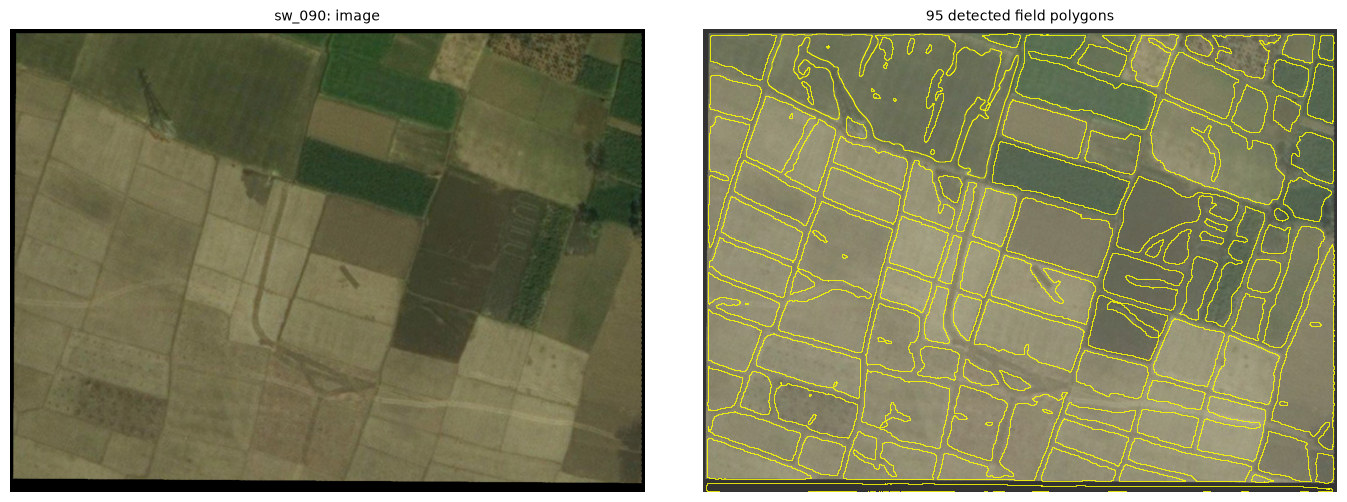

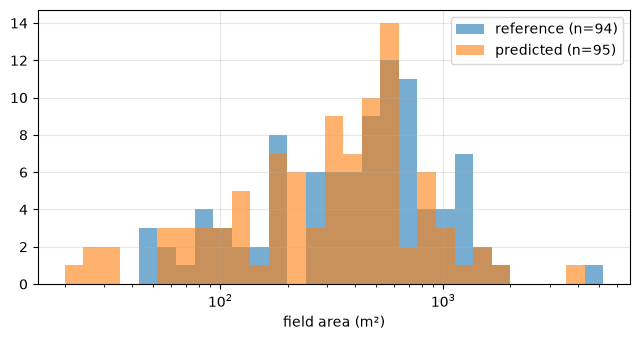

median area: reference 467 m², predicted 349 m²


In [ ]:
ref_area = np.bincount(d["inst"].ravel())[1:] * GSD ** 2    # reference field areas in m²
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(d["img"]); ax[0].set_title(f"{tile}: image")
ext = d["bounds"]                                            # left, bottom, right, top in map units
ax[1].imshow(d["img"], alpha=0.8)
# Convert the polygons from map coordinates to pixel coordinates so they line up with the image.
fields.assign(geometry=fields.geometry.apply(lambda g: shapely.affinity.affine_transform(g, [1 / GSD, 0, 0, -1 / GSD, -ext[0] / GSD, ext[3] / GSD]))).boundary.plot(ax=ax[1], color="yellow", linewidth=0.6)
ax[1].set_title(f"{len(fields)} detected field polygons"); [a.axis("off") for a in ax]
plt.tight_layout(); plt.show()

# Field-size distributions of the reference and the prediction, on a logarithmic area axis.
bins = np.geomspace(20, max(fields.area_m2.max(), ref_area.max()), 30)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.hist(ref_area, bins, alpha=.6, label=f"reference (n={len(ref_area)})"); ax.hist(fields.area_m2, bins, alpha=.6, label=f"predicted (n={len(fields)})")
ax.set_xscale("log"); ax.set_xlabel("field area (m²)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"median area: reference {np.median(ref_area):.0f} m², predicted {fields.area_m2.median():.0f} m²")

## Limitations and a Practical Workflow

**What the scores mean.** They measure agreement with *this* digitisation of *these* screenshots. A field the annotator did not outline, or a bund too faint to see, counts against a model that is arguably right. The Test set is two sites (sw_09 and sw_10), so the differences between models that are close to each other are not statistically firm; the per-tile boxplots of the held-out test evaluation show the spread.

**About the imagery.** The tiles are Google basemap screenshots. The acquisition date and sensor are unknown and may differ between tiles, the 1.9 cm pixel size comes from interpolation (the real detail is far coarser, which is why the work is done at 0.25 m), and the licence restricts re-use of the screenshots themselves.

**About the comparison.** The released FC-DenseNet checkpoints use their own training schedule and were trained on the same Train tiles; the networks trained here simply run longer (`STEPS`). The fine-tuned DA checkpoint was also trained on these Train tiles. SAM 2.1 is used pre-trained only (`ed.load_sam2` does not load the fine-tuned decoder), and the SAM 2 prompt grid was tuned on three Valid tiles only.

**Practical workflow.**

1. Resample imagery to about 0.25 m in a projected CRS before using any of these models.
2. Start with a pre-trained instance model (SAM 2.1 or DA) as a zero-training baseline, and compare it with a boundary model trained on a few dozen labelled tiles from your own area.
3. Choose thresholds on a held-out Valid set, never on Test.
4. Export polygons with `detect_field_edges_from_raster`, filter by `area_m2` and `score`, and review a sample against the imagery before using the areas.


## Summary

**Results on the 12 held-out Test tiles** (instance $F_1$ at IoU $>0.5$; boundary $F_1$ within 2 m):

| model | instance $F_1$ | boundary $F_1$@2 m |
|---|---|---|
| FC-DenseNet103 (trained here) | 0.64 | 0.74 |
| FC-DenseNet67 (trained here) | 0.62 | 0.68 |
| FC-DenseNet56 (trained here) | 0.61 | 0.72 |
| SAM 2.1 (automatic masks) | 0.55 | 0.74 |
| Delineate Anything V2, fine-tuned | 0.50 | 0.73 |
| Delineate Anything V2, pre-trained | 0.42 | 0.67 |
| FC-DenseNet released checkpoints (103 / 67 / 56) | 0.36 / 0.32 / 0.23 | 0.58 / 0.53 / 0.39 |
| Classical Sobel + Sato | 0.13 | 0.57 |

**What the numbers say.**

- A supervised boundary network is the strongest option here, and it needs only 36 labelled tiles and about 5 to 8 minutes of GPU time per model. The three presets are close (0.61 to 0.64); with two Test sites, the ordering among them should not be over-read.
- SAM 2.1 needs no training and has the highest precision (0.72) but the lowest recall of the strong models, since masks that fail the quality filters are dropped. It places edges as well as the trained networks: it has the best 1 m boundary $F_1$ (0.61) and ties them at 2 m. On the two weakest tiles (sw_094 and sw_095), where the FC-DenseNets fall to 0.3 to 0.4, it keeps 0.5 to 0.54.
- Fine-tuning helps DA V2 (0.42 to 0.50), mostly through recall and a higher confidence setting.
- The classical filter finds edges roughly where the annotator drew them (boundary $F_1$@2 m of 0.57), but it cannot close them, so it merges fields; its instance $F_1$ is only 0.13. Boundary location and field recovery are different things.
- The released FC-DenseNet checkpoints score well below the models trained here, although they were trained on the same Train tiles, so the gap reflects training length and recipe, not data. The 6 to 10 minute in-notebook training used far more crops (1,500 steps of 8) than the original 25 epochs of 16 batches of 4.
- The best threshold for the boundary networks is low (0.1 to 0.2), well under 0.5, because a partial barrier is enough to separate two fields while a gap lets them merge.

**Caveats.** The scores measure agreement with one hand digitisation, on two Test sites, and the screenshots are basemap imagery with unknown date and sensor. Treat model differences below about 0.05 as within noise.
